In [1]:
from pathlib import Path
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import sklearn

# Dataset location
DATASET_DIR = (
    Path.home()
    / "Downloads"
    / "Rice Leaf Disease Image Samples"
    / "Rice Leaf Disease Images"
)

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Dataset exists:", DATASET_DIR.is_dir())

class_names = sorted(
    folder.name for folder in DATASET_DIR.iterdir()
    if folder.is_dir()
)

print("\nDisease classes:", class_names)

TensorFlow version: 2.22.0-rc0
NumPy version: 2.5.4
Scikit-learn version: 1.9.1
Dataset exists: True

Disease classes: ['Bacterialblight', 'Blast', 'Brownspot', 'Tungro']


RICE LEAF DISEASE DATASET
Bacterialblight: 1584 images
Blast: 1440 images
Brownspot: 1600 images
Tungro: 1308 images

Total images: 5932


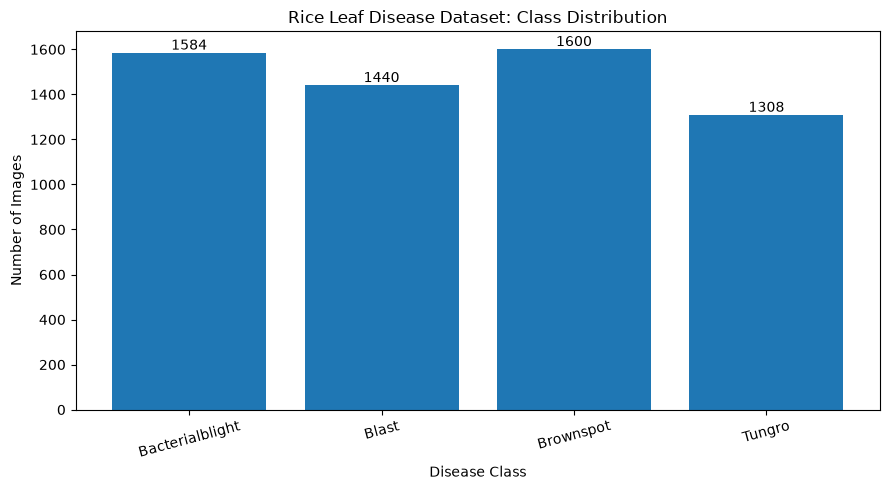

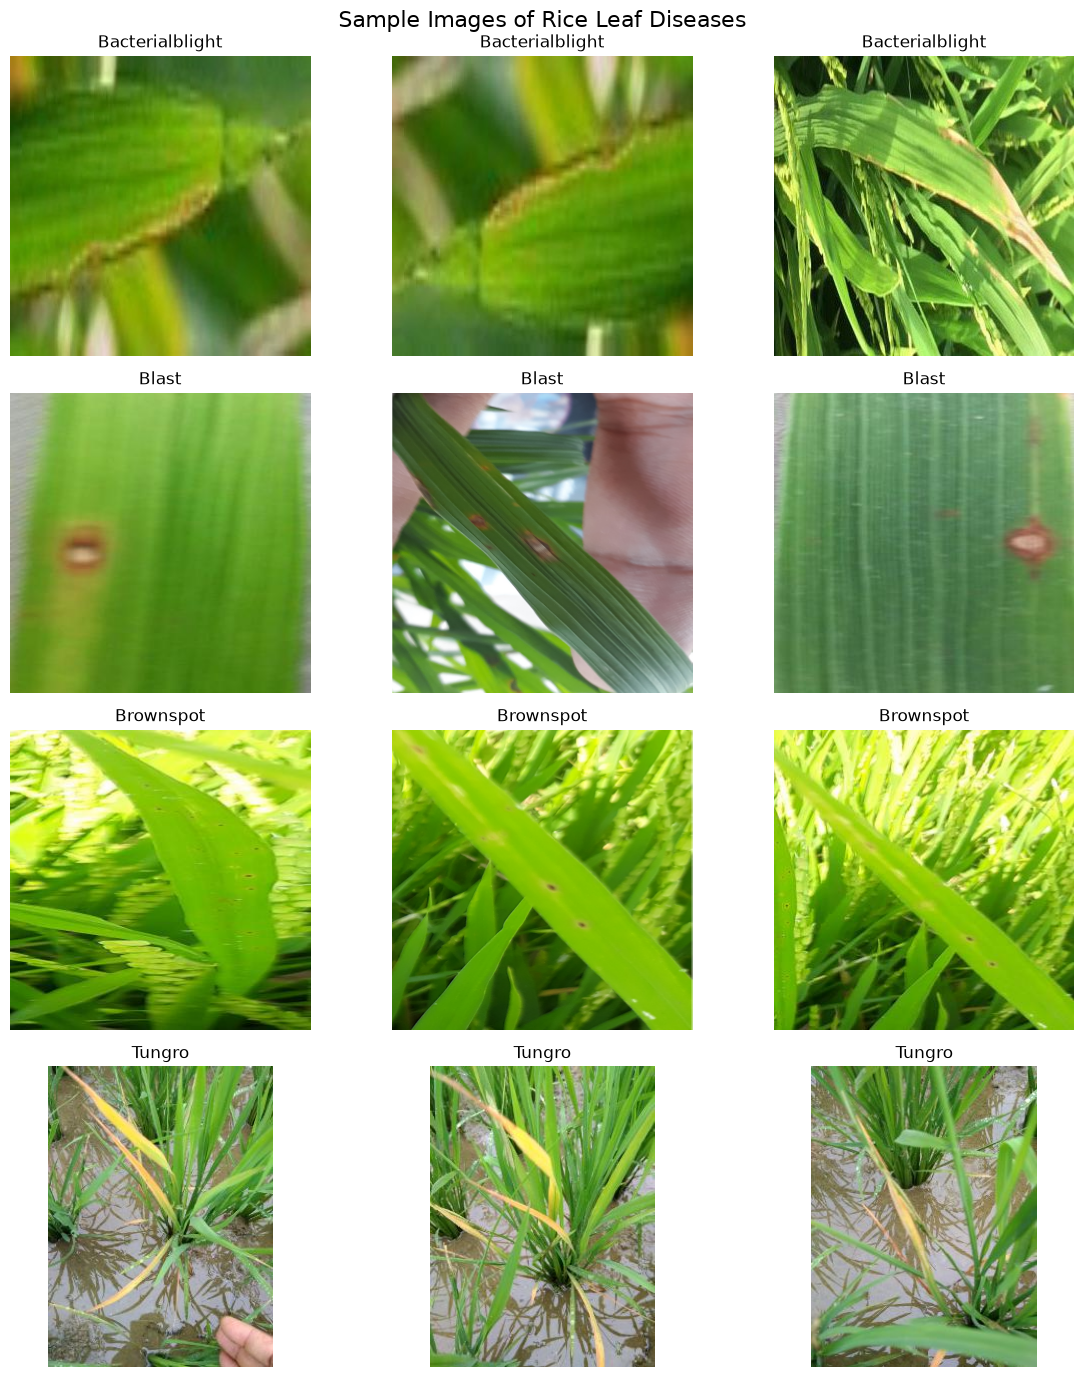

In [2]:
# Cell 2: Dataset exploration

from collections import Counter
import matplotlib.pyplot as plt
from PIL import Image

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Collect images for each disease class
class_images = {}

for class_name in class_names:
    folder = DATASET_DIR / class_name

    images = sorted(
        file for file in folder.iterdir()
        if file.is_file()
        and file.suffix.lower() in IMAGE_EXTENSIONS
    )

    class_images[class_name] = images

# Display image counts
print("RICE LEAF DISEASE DATASET")
print("=" * 35)

for class_name, images in class_images.items():
    print(f"{class_name}: {len(images)} images")

total_images = sum(len(images) for images in class_images.values())
print(f"\nTotal images: {total_images}")

# Plot class distribution
plt.figure(figsize=(9, 5))
bars = plt.bar(
    class_images.keys(),
    [len(images) for images in class_images.values()]
)

plt.bar_label(bars)
plt.title("Rice Leaf Disease Dataset: Class Distribution")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Display three sample images from each class
fig, axes = plt.subplots(4, 3, figsize=(12, 14))

for row, class_name in enumerate(class_names):
    for col in range(3):
        image_path = class_images[class_name][col]

        with Image.open(image_path) as image:
            axes[row, col].imshow(image.convert("RGB"))

        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.suptitle("Sample Images of Rice Leaf Diseases", fontsize=16)
plt.tight_layout()
plt.show()

In [3]:
# Cell 3: Reproducible train, validation and test split

from sklearn.model_selection import train_test_split
from collections import Counter

RANDOM_SEED = 42

# Create a list of image paths and their class labels
all_image_paths = []
all_labels = []

for class_index, class_name in enumerate(class_names):
    for image_path in class_images[class_name]:
        all_image_paths.append(str(image_path))
        all_labels.append(class_index)

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    all_image_paths,
    all_labels,
    test_size=0.30,
    random_state=RANDOM_SEED,
    stratify=all_labels
)

# Second split: 15% validation, 15% test overall
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_SEED,
    stratify=y_temp
)

# Report split sizes
print("DATASET SPLIT SUMMARY")
print("=" * 35)
print(f"Training images:   {len(X_train)} ({len(X_train)/len(all_image_paths):.1%})")
print(f"Validation images: {len(X_val)} ({len(X_val)/len(all_image_paths):.1%})")
print(f"Test images:       {len(X_test)} ({len(X_test)/len(all_image_paths):.1%})")
print(f"Total images:      {len(all_image_paths)}")
print(f"Random seed:       {RANDOM_SEED}")

# Show class distribution in each split
print("\nCLASS DISTRIBUTION BY SPLIT")

for split_name, labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    counts = Counter(labels)
    print(f"\n{split_name}:")
    for class_index, class_name in enumerate(class_names):
        print(f"  {class_name}: {counts[class_index]}")

DATASET SPLIT SUMMARY
Training images:   4152 (70.0%)
Validation images: 890 (15.0%)
Test images:       890 (15.0%)
Total images:      5932
Random seed:       42

CLASS DISTRIBUTION BY SPLIT

Training:
  Bacterialblight: 1109
  Blast: 1008
  Brownspot: 1120
  Tungro: 915

Validation:
  Bacterialblight: 237
  Blast: 216
  Brownspot: 240
  Tungro: 197

Test:
  Bacterialblight: 238
  Blast: 216
  Brownspot: 240
  Tungro: 196


In [4]:

# Cell 4: Prepare image datasets for CNN training

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Convert paths and labels into TensorFlow datasets
def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def create_dataset(paths, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=RANDOM_SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

train_ds = create_dataset(X_train, y_train, training=True)
val_ds = create_dataset(X_val, y_val)
test_ds = create_dataset(X_test, y_test)

# Verify one batch
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel value range:",
          float(tf.reduce_min(images)),
          "to",
          float(tf.reduce_max(images)))

print("\nTraining, validation and test datasets are ready.")
print("Class names:", class_names)


Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)
Pixel value range: 0.0 to 1.0

Training, validation and test datasets are ready.
Class names: ['Bacterialblight', 'Blast', 'Brownspot', 'Tungro']


In [5]:

# Cell 5: Build the Convolutional Neural Network (CNN)

from tensorflow import keras
from tensorflow.keras import layers

NUM_CLASSES = len(class_names)

model = keras.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # Convolution block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,276 (430.77 KB)

 Trainable params: 110,276 (430.77 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:

# Cell 6: Train the CNN model

import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras

# Set seeds for reproducibility
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

EPOCHS = 15

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        "best_rice_disease_cnn.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

print("\nTraining completed.")
print("Best validation accuracy:",
      f"{max(history.history['val_accuracy']):.4f}")


Epoch 1/15


/Users/josephinesherly/Documents/RiceDiseaseProject/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.4750 - loss: 1.1700
Epoch 1: val_loss improved from None to 0.83970, saving model to best_rice_disease_cnn.keras

Epoch 1: finished saving model to best_rice_disease_cnn.keras
130/130 ━━━━━━━━━━━━━━━━━━━━ 16s 121ms/step - accuracy: 0.4750 - loss: 1.1700 - val_accuracy: 0.6787 - val_loss: 0.8397
Epoch 2/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - accuracy: 0.6578 - loss: 0.8630
Epoch 2: val_loss improved from 0.83970 to 0.66562, saving model to best_rice_disease_cnn.keras

Epoch 2: finished saving model to best_rice_disease_cnn.keras
130/130 ━━━━━━━━━━━━━━━━━━━━ 16s 124ms/step - accuracy: 0.6578 - loss: 0.8630 - val_accuracy: 0.7494 - val_loss: 0.6656
Epoch 3/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 0.7276 - loss: 0.7020
Epoch 3: val_loss improved from 0.66562 to 0.61379, saving model to best_rice_disease_cnn.keras

Epoch 3: finished saving model to best_rice_disease_cnn.keras
130/130 ━━━━━━━━━━━━━━━━━━━━ 17s 

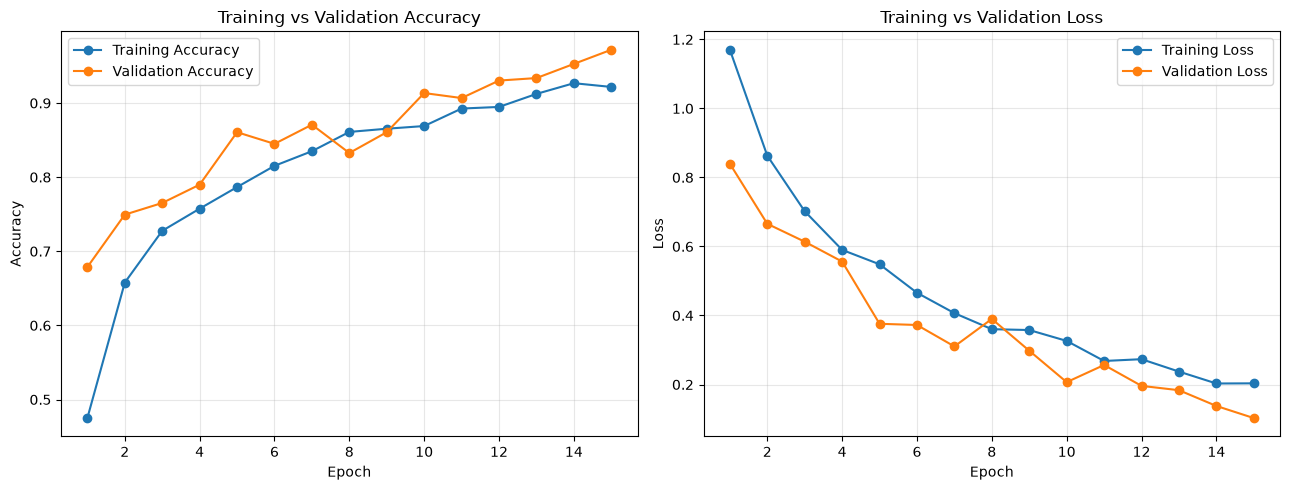

Saved training_validation_curves.png


In [7]:

# Cell 7: Plot training and validation curves

import matplotlib.pyplot as plt

epochs_ran = range(1, len(history.history["accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Accuracy curve
axes[0].plot(
    epochs_ran, history.history["accuracy"],
    marker="o", label="Training Accuracy"
)
axes[0].plot(
    epochs_ran, history.history["val_accuracy"],
    marker="o", label="Validation Accuracy"
)
axes[0].set_title("Training vs Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss curve
axes[1].plot(
    epochs_ran, history.history["loss"],
    marker="o", label="Training Loss"
)
axes[1].plot(
    epochs_ran, history.history["val_loss"],
    marker="o", label="Validation Loss"
)
axes[1].set_title("Training vs Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("training_validation_curves.png", dpi=200)
plt.show()

print("Saved training_validation_curves.png")


In [8]:

# Cell 8: Evaluate on the held-out test set

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"\nTest loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4%}")


28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.9629 - loss: 0.1136

Test loss: 0.1136
Test accuracy: 96.2921%


In [9]:

# Cell 9: Detailed test-set evaluation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Predict probabilities for every test image
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Get true labels in the same order as test_ds
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

# Classification report
print("CLASSIFICATION REPORT")
print("=" * 65)

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(report)

# Macro F1-score and test accuracy
from sklearn.metrics import f1_score

print(f"Test accuracy: {accuracy_score(y_true, y_pred):.4%}")
print(f"Macro F1-score: {f1_score(y_true, y_pred, average='macro'):.4f}")

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix — Rice Leaf Disease CNN")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.xticks(rotation=20)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=200)
plt.show()

print("Saved confusion_matrix.png")


ModuleNotFoundError: No module named 'pandas'

In [ ]:
%pip install pandas seaborn

In [ ]:

# Cell 9: Detailed test-set evaluation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Predict probabilities for every test image
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Get true labels in the same order as test_ds
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

# Classification report
print("CLASSIFICATION REPORT")
print("=" * 65)

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(report)

# Macro F1-score and test accuracy
from sklearn.metrics import f1_score

print(f"Test accuracy: {accuracy_score(y_true, y_pred):.4%}")
print(f"Macro F1-score: {f1_score(y_true, y_pred, average='macro'):.4f}")

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix — Rice Leaf Disease CNN")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.xticks(rotation=20)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=200)
plt.show()

print("Saved confusion_matrix.png")


In [14]:
%pip install pandas seaborn

  Using cached pandas-3.1.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (18 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 7.3 MB/s  0:00:017.6 MB/s eta 0:00:0101m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [seaborn]
Note: you may need to restart the kernel to use updated packages.


In [13]:
%pip install pandas seaborn

  Using cached pandas-3.1.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (18 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
   ━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.5/11.3 MB ? eta -:--:--
Resuming download pandas-3.1.0-cp314-cp314-macosx_11_0_arm64.whl (524 kB/11.3 MB)
   ━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.5/11.3 MB ? eta -:--:--0m
error: incomplete-download

× Download failed after 6 attempts because not enough bytes were received (524 kB/11.3 MB)
╰─> URL: https://files.pythonhosted.org/packages/83/38/6be618d98e2cbbb99a40349717532f0c2b6794ddc62f1199e3f83e45a40f/pandas-3.1.0-cp314-cp314-macosx_11_0_arm64.whl

note: This is an issue with network connectivity, not pip.
hint: Use --resume-retries to configure resume attempt limit.
Note: you may need to restart the kernel to use updated packages.


28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step
CLASSIFICATION REPORT
                 precision    recall  f1-score   support

Bacterialblight     0.9868    0.9454    0.9657       238
          Blast     0.8979    0.9769    0.9357       216
      Brownspot     0.9869    0.9417    0.9638       240
         Tungro     0.9848    0.9949    0.9898       196

       accuracy                         0.9629       890
      macro avg     0.9641    0.9647    0.9637       890
   weighted avg     0.9648    0.9629    0.9632       890

Test accuracy: 96.2921%
Macro F1-score: 0.9637


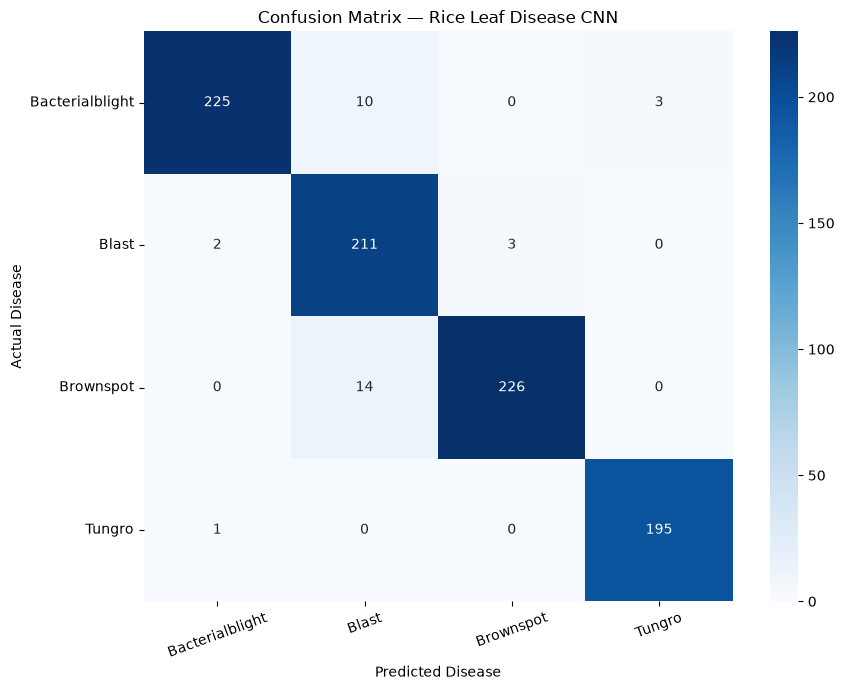

Saved confusion_matrix.png


In [15]:

# Cell 9: Detailed test-set evaluation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Predict probabilities for every test image
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Get true labels in the same order as test_ds
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

# Classification report
print("CLASSIFICATION REPORT")
print("=" * 65)

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(report)

# Macro F1-score and test accuracy
from sklearn.metrics import f1_score

print(f"Test accuracy: {accuracy_score(y_true, y_pred):.4%}")
print(f"Macro F1-score: {f1_score(y_true, y_pred, average='macro'):.4f}")

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix — Rice Leaf Disease CNN")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.xticks(rotation=20)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=200)
plt.show()

print("Saved confusion_matrix.png")


28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step
Total misclassified images: 33
Displaying up to 8 misclassified images


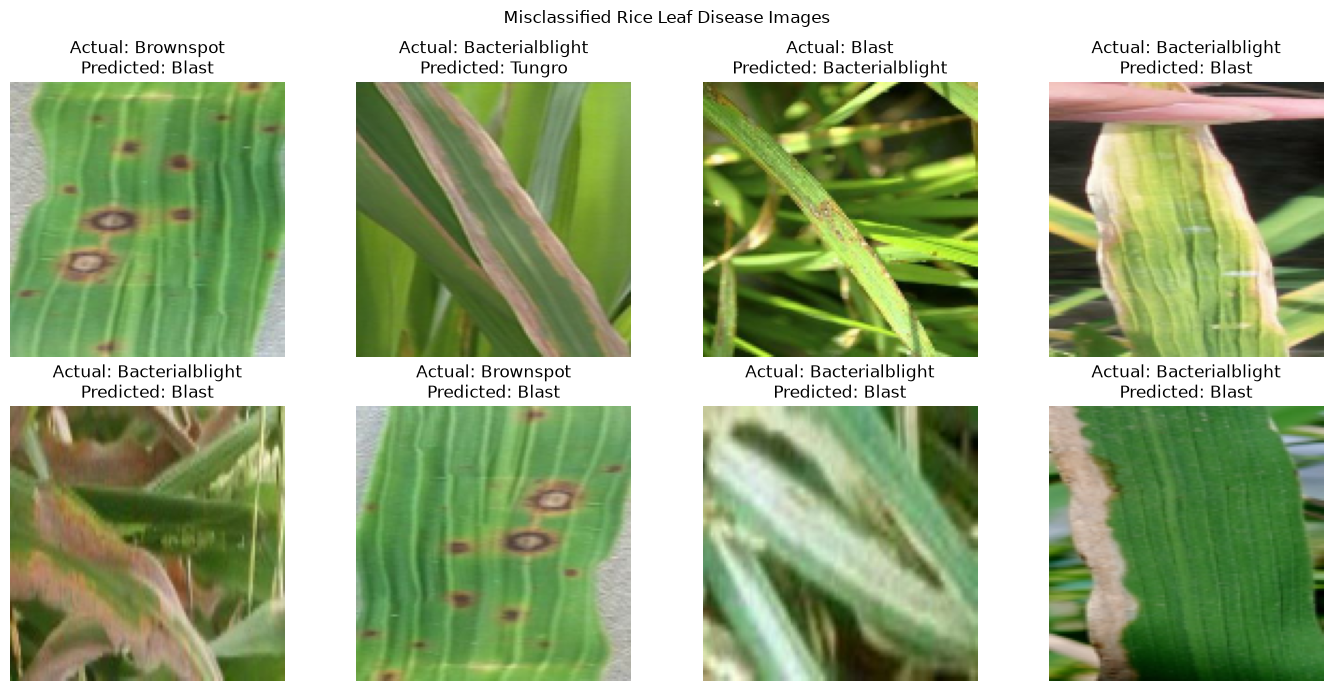

Saved misclassified_test_images.png


In [16]:
# Cell 10: Display misclassified test images

import matplotlib.pyplot as plt
import numpy as np

# Collect test images and true labels
test_images = []
true_labels = []

for images, labels in test_ds:
    test_images.extend(images.numpy())
    true_labels.extend(labels.numpy())

test_images = np.array(test_images)
true_labels = np.array(true_labels)

# Get model predictions
probabilities = model.predict(test_ds, verbose=1)
predicted_labels = np.argmax(probabilities, axis=1)

# Find incorrectly classified images
wrong_indices = np.where(true_labels != predicted_labels)[0]

print("Total misclassified images:", len(wrong_indices))
print("Displaying up to 8 misclassified images")

# Display up to 8 errors
n = min(8, len(wrong_indices))
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for i in range(8):
    if i < n:
        idx = wrong_indices[i]
        axes[i].imshow(test_images[idx])
        axes[i].set_title(
            f"Actual: {class_names[true_labels[idx]]}\n"
            f"Predicted: {class_names[predicted_labels[idx]]}"
        )
    axes[i].axis("off")

plt.suptitle("Misclassified Rice Leaf Disease Images")
plt.tight_layout()
plt.savefig("misclassified_test_images.png", dpi=200)
plt.show()

print("Saved misclassified_test_images.png")

In [17]:
# Cell 11: Save evaluation results

import pandas as pd
from sklearn.metrics import classification_report, accuracy_score, f1_score

report_dict = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

results_df = pd.DataFrame(report_dict).transpose()
results_df.to_csv("classification_report.csv")

summary_df = pd.DataFrame({
    "Metric": ["Test Accuracy", "Macro F1-score", "Total Test Images",
               "Misclassified Images"],
    "Value": [
        accuracy_score(y_true, y_pred),
        f1_score(y_true, y_pred, average="macro"),
        len(y_true),
        int(np.sum(y_true != y_pred))
    ]
})

summary_df.to_csv("evaluation_summary.csv", index=False)

print("Saved classification_report.csv")
print("Saved evaluation_summary.csv")
print("\nEVALUATION SUMMARY")
print(summary_df.to_string(index=False))

Saved classification_report.csv
Saved evaluation_summary.csv

EVALUATION SUMMARY
              Metric      Value
       Test Accuracy   0.962921
      Macro F1-score   0.963741
   Total Test Images 890.000000
Misclassified Images  33.000000


In [18]:
from pathlib import Path

files_to_check = [
    "best_rice_disease_cnn.keras",
    "training_validation_curves.png",
    "confusion_matrix.png",
    "misclassified_test_images.png",
    "classification_report.csv",
    "evaluation_summary.csv"
]

for filename in files_to_check:
    path = Path(filename)
    print(f"{filename}: {'FOUND' if path.exists() else 'NOT FOUND'}")

best_rice_disease_cnn.keras: FOUND
training_validation_curves.png: FOUND
confusion_matrix.png: FOUND
misclassified_test_images.png: FOUND
classification_report.csv: FOUND
evaluation_summary.csv: FOUND


In [19]:
from pathlib import Path
import shutil

submission = Path("Rice_Disease_Submission")
submission.mkdir(exist_ok=True)

files_to_copy = [
    "best_rice_disease_cnn.keras",
    "training_validation_curves.png",
    "confusion_matrix.png",
    "misclassified_test_images.png",
    "classification_report.csv",
    "evaluation_summary.csv"
]

for filename in files_to_copy:
    source = Path(filename)
    if source.exists():
        shutil.copy2(source, submission / filename)
        print("Copied:", filename)
    else:
        print("Missing:", filename)

print("\nSubmission folder:", submission.resolve())

Copied: best_rice_disease_cnn.keras
Copied: training_validation_curves.png
Copied: confusion_matrix.png
Copied: misclassified_test_images.png
Copied: classification_report.csv
Copied: evaluation_summary.csv

Submission folder: /Users/josephinesherly/Documents/RiceDiseaseProject/Rice_Disease_Submission


In [20]:
import shutil
from pathlib import Path

folder = Path("Rice_Disease_Submission")

zip_path = shutil.make_archive(
    str(folder.resolve()),
    "zip",
    root_dir=folder.resolve()
)

print("ZIP backup created at:")
print(zip_path)
print("Size (MB):", round(Path(zip_path).stat().st_size / (1024 * 1024), 2))

ZIP backup created at:
/Users/josephinesherly/Documents/RiceDiseaseProject/Rice_Disease_Submission.zip
Size (MB): 1.82
